<a href="https://colab.research.google.com/github/naylanara89/ProyekAkhir_A_Avocado/blob/main/notebook/01_Eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Eksplorasi Data (EDA)

**Dataset: Avocado Prices**


## Step 0 — Mengenal sumber dan isi dataset

Dataset Avocado Prices berisi catatan penjualan alpukat Hass secara mingguan di berbagai wilayah Amerika Serikat. Satu baris mewakili satu minggu, satu wilayah, dan satu jenis alpukat. Data mencakup harga rata-rata, volume penjualan, jenis kemasan/ukuran, tahun, serta wilayah.

Keterbatasannya: data ini tidak memuat identitas pembeli, demografi konsumen, biaya produksi, atau informasi yang cukup untuk menyimpulkan hubungan sebab-akibat. `region` juga memuat wilayah agregat seperti `TotalUS`, sehingga wilayah agregat perlu dipisahkan dari wilayah detail.

Sumber dataset asli: https://www.kaggle.com/datasets/neuromusic/avocado-prices

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

### Kamus data singkat
- `Date`: tanggal pencatatan mingguan.
- `AveragePrice`: harga rata-rata satu buah alpukat.
- `Total Volume`: total volume alpukat terjual.
- `4046`, `4225`, `4770`: volume berdasarkan kode PLU.
- `Total Bags`: total volume penjualan dalam kantong; rinciannya ada pada `Small Bags`, `Large Bags`, dan `XLarge Bags`.
- `type`: jenis alpukat, conventional atau organic.
- `year`: tahun pencatatan.
- `region`: wilayah pencatatan.

## Step 1 — Memuat data



In [ ]:
# Sumber dataset asli: Kaggle - Avocado Prices
kaggle_url = 'https://www.kaggle.com/datasets/neuromusic/avocado-prices'

from google.colab import files
uploaded = files.upload()

csv_files = [nama for nama in uploaded.keys() if nama.lower().endswith('.csv')]
if not csv_files:
    raise FileNotFoundError('File CSV belum dipilih. Jalankan ulang sel ini dan pilih avocado.csv.')

nama_file = csv_files[0]
df = pd.read_csv(nama_file)

print('Sumber dataset:', kaggle_url)
print('File yang dibaca:', nama_file)
print('Ukuran data:', df.shape)
df.head()

Saving avocado.csv to avocado.csv
Sumber dataset: https://www.kaggle.com/datasets/neuromusic/avocado-prices
File yang dibaca: avocado.csv
Ukuran data: (18249, 14)


,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,"64,236.62","1,036.74","54,454.85",48.16,"8,696.87","8,603.62",93.25,0.00,conventional,2015,Albany
1,1,2015-12-20,1.35,"54,876.98",674.28,"44,638.81",58.33,"9,505.56","9,408.07",97.49,0.00,conventional,2015,Albany
2,2,2015-12-13,0.93,"118,220.22",794.70,"109,149.67",130.50,"8,145.35","8,042.21",103.14,0.00,conventional,2015,Albany
3,3,2015-12-06,1.08,"78,992.15","1,132.00","71,976.41",72.58,"5,811.16","5,677.40",133.76,0.00,conventional,2015,Albany
4,4,2015-11-29,1.28,"51,039.60",941.48,"43,838.39",75.78,"6,183.95","5,986.26",197.69,0.00,conventional,2015,Albany


## Step 2 — Memeriksa struktur dan unit analisis

In [ ]:
df.info()
display(df.describe(include='all').T)
print('Jumlah baris:', len(df))
print('Jumlah kolom:', len(df.columns))
print('Jumlah wilayah:', df['region'].nunique() if 'region' in df else '-')
print('Rentang tanggal:', df['Date'].min(), 'sampai', df['Date'].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), int64(2), object(3)
memory usage: 1.9+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,"18,249.00",NaN,NaN,NaN,24.23,15.48,0.00,10.00,24.00,38.00,52.00
Date,18249,169,2015-12-27,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AveragePrice,"18,249.00",NaN,NaN,NaN,1.41,0.40,0.44,1.10,1.37,1.66,3.25
Total Volume,"18,249.00",NaN,NaN,NaN,"850,644.01","3,453,545.36",84.56,"10,838.58","107,376.76","432,962.29","62,505,646.52"
4046,"18,249.00",NaN,NaN,NaN,"293,008.42","1,264,989.08",0.00,854.07,"8,645.30","111,020.20","22,743,616.17"
4225,"18,249.00",NaN,NaN,NaN,"295,154.57","1,204,120.40",0.00,"3,008.78","29,061.02","150,206.86","20,470,572.61"
4770,"18,249.00",NaN,NaN,NaN,"22,839.74","107,464.07",0.00,0.00,184.99,"6,243.42","2,546,439.11"
Total Bags,"18,249.00",NaN,NaN,NaN,"239,639.20","986,242.40",0.00,"5,088.64","39,743.83","110,783.37","19,373,134.37"
Small Bags,"18,249.00",NaN,NaN,NaN,"182,194.69","746,178.51",0.00,"2,849.42","26,362.82","83,337.67","13,384,586.80"
Large Bags,"18,249.00",NaN,NaN,NaN,"54,338.09","243,965.96",0.00,127.47,"2,647.71","22,029.25","5,719,096.61"


Jumlah baris: 18249
Jumlah kolom: 14
Jumlah wilayah: 54
Rentang tanggal: 2015-01-04 sampai 2018-03-25


Unit analisisnya adalah satu pengamatan mingguan untuk kombinasi wilayah dan jenis alpukat. Karena ada pengamatan berulang pada wilayah yang sama dari waktu ke waktu, baris data tidak sepenuhnya independen.

## Step 3 — Memeriksa kebersihan data

In [ ]:
print('Missing value per kolom:')
display(df.isna().sum().to_frame('jumlah_missing'))
print('Jumlah duplikat:', df.duplicated().sum())
print('Jumlah nilai unik per kolom:')
display(df.nunique().to_frame('nilai_unik'))
print('Kategori type:', df['type'].value_counts(dropna=False))
print('Kategori region:', df['region'].nunique())

Missing value per kolom:


,jumlah_missing
Unnamed: 0,0
Date,0
AveragePrice,0
Total Volume,0
4046,0
4225,0
4770,0
Total Bags,0
Small Bags,0
Large Bags,0


Jumlah duplikat: 0
Jumlah nilai unik per kolom:


,nilai_unik
Unnamed: 0,53
Date,169
AveragePrice,259
Total Volume,18237
4046,17702
4225,18103
4770,12071
Total Bags,18097
Small Bags,17321
Large Bags,15082


Kategori type: type
conventional    9126
organic         9123
Name: count, dtype: int64
Kategori region: 54


In [ ]:
# Memeriksa nilai numerik yang tidak wajar
num_cols = df.select_dtypes(include=np.number).columns
display(df[num_cols].describe().T)
print('Nilai AveragePrice <= 0:', (df['AveragePrice'] <= 0).sum())
print('Nilai volume negatif:', (df[[x for x in num_cols if x not in ['year']]] < 0).sum())

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"18,249.00",24.23,15.48,0.00,10.00,24.00,38.00,52.00
AveragePrice,"18,249.00",1.41,0.40,0.44,1.10,1.37,1.66,3.25
Total Volume,"18,249.00","850,644.01","3,453,545.36",84.56,"10,838.58","107,376.76","432,962.29","62,505,646.52"
4046,"18,249.00","293,008.42","1,264,989.08",0.00,854.07,"8,645.30","111,020.20","22,743,616.17"
4225,"18,249.00","295,154.57","1,204,120.40",0.00,"3,008.78","29,061.02","150,206.86","20,470,572.61"
4770,"18,249.00","22,839.74","107,464.07",0.00,0.00,184.99,"6,243.42","2,546,439.11"
Total Bags,"18,249.00","239,639.20","986,242.40",0.00,"5,088.64","39,743.83","110,783.37","19,373,134.37"
Small Bags,"18,249.00","182,194.69","746,178.51",0.00,"2,849.42","26,362.82","83,337.67","13,384,586.80"
Large Bags,"18,249.00","54,338.09","243,965.96",0.00,127.47,"2,647.71","22,029.25","5,719,096.61"
XLarge Bags,"18,249.00","3,106.43","17,692.89",0.00,0.00,0.00,132.50,"551,693.65"


Nilai AveragePrice <= 0: 0
Nilai volume negatif: Unnamed: 0      0
AveragePrice    0
Total Volume    0
4046            0
4225            0
4770            0
Total Bags      0
Small Bags      0
Large Bags      0
XLarge Bags     0
dtype: int64


Pemeriksaan dilakukan untuk menemukan nilai kosong, duplikat, kategori yang tidak konsisten, nilai konstan, dan nilai numerik yang tidak masuk akal. Nilai ekstrem tidak langsung dihapus karena volume penjualan yang besar masih mungkin terjadi pada wilayah agregat.

## Step 4 — Memahami target klasifikasi (`type`)

In [ ]:
target_count = df['type'].value_counts()
target_pct = df['type'].value_counts(normalize=True).mul(100)
target_summary = pd.DataFrame({'jumlah': target_count, 'persentase': target_pct.round(2)})
display(target_summary)
majority_baseline = target_count.max() / target_count.sum()
print(f'Majority-class baseline: {majority_baseline:.2%}')


,jumlah,persentase
type,,
conventional,9126,50.01
organic,9123,49.99


Majority-class baseline: 50.01%


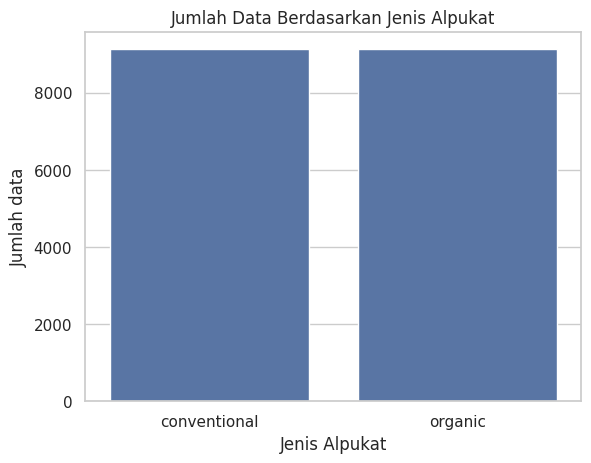

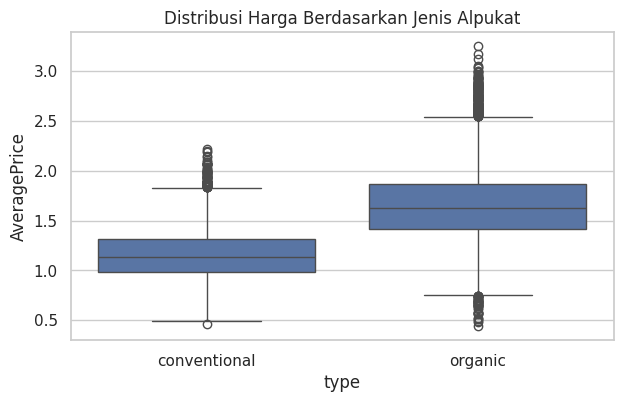

In [ ]:
sns.countplot(data=df, x='type')
plt.title('Jumlah Data Berdasarkan Jenis Alpukat')
plt.xlabel('Jenis Alpukat'); plt.ylabel('Jumlah data'); plt.show()

plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='type', y='AveragePrice')
plt.title('Distribusi Harga Berdasarkan Jenis Alpukat')
plt.show()

Target `type` memiliki dua kelas. Proporsi kelas perlu diperhatikan sebelum pemodelan; baseline kelas mayoritas menjadi pembanding sederhana. Boxplot harga membantu melihat apakah harga berbeda antarjenis, tetapi harga bukan pemisah kelas yang otomatis sempurna. Jika model berbasis jarak seperti KNN digunakan nanti, fitur numerik perlu diskalakan setelah pembagian data. Untuk Naive Bayes, asumsi independensi fitur perlu diperhatikan.

## Step 5 — Hubungan antarvariabel dan potensi kebocoran

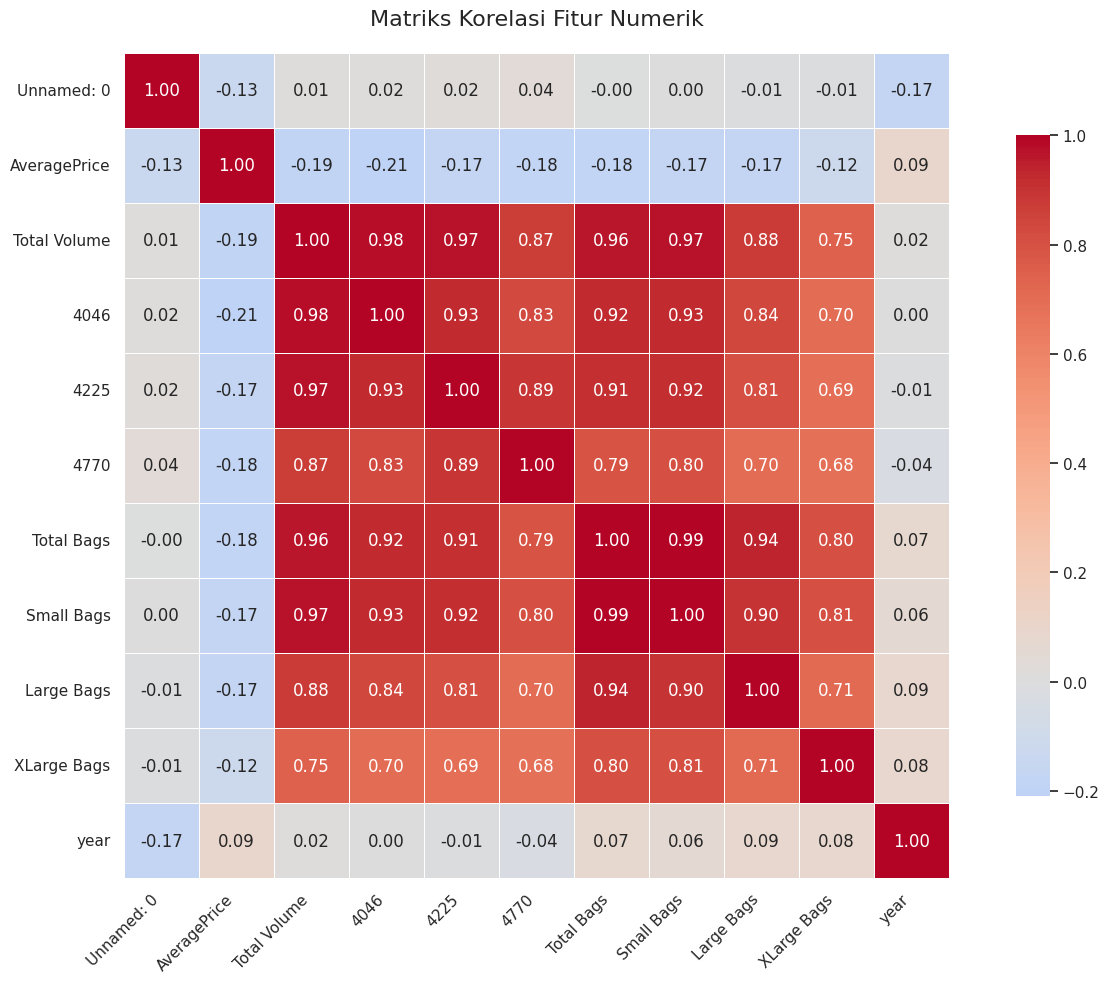

Pasangan variabel dengan korelasi absolut di atas 0.80:


Korelasi Absolut
Total Bags   Small Bags               0.99
Total Volume 4046                     0.98
             4225                     0.97
             Small Bags               0.97
             Total Bags               0.96
Total Bags   Large Bags               0.94
4046         4225                     0.93
             Small Bags               0.93
             Total Bags               0.92
4225         Small Bags               0.92
             Total Bags               0.91
Small Bags   Large Bags               0.90
4225         4770                     0.89
Total Volume Large Bags               0.88
             4770                     0.87
4046         Large Bags               0.84
             4770                     0.83
4225         Large Bags               0.81
Small Bags   XLarge Bags              0.81
Total Bags   XLarge Bags              0.80
4770         Small Bags               0.80

In [ ]:
# Korelasi numerik
num_df = df.select_dtypes(include=np.number)
corr = num_df.corr(numeric_only=True)

# Membuat ukuran gambar lebih besar
plt.figure(figsize=(14, 10))

# Menampilkan heatmap dengan angka korelasi
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)

plt.title('Matriks Korelasi Fitur Numerik', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Menampilkan pasangan dengan korelasi absolut di atas 0.80
pairs = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

print('Pasangan variabel dengan korelasi absolut di atas 0.80:')
display(
    pairs[pairs > 0.80]
    .sort_values(ascending=False)
    .to_frame('Korelasi Absolut')
)

`Total Volume` merupakan penjumlahan komponen volume PLU, sedangkan `Total Bags` merupakan penjumlahan `Small Bags`, `Large Bags`, dan `XLarge Bags`. Memakai nilai total bersama komponen penyusunnya dapat menimbulkan multikolinearitas yang bersifat definisional. Kolom agregat tersebut akan dihilangkan pada preprocessing. Pemeriksaan korelasi juga membantu mengenali fitur yang sangat berkaitan, tetapi korelasi tidak membuktikan sebab-akibat.

## Step 6 — Visualisasi untuk menjawab pertanyaan

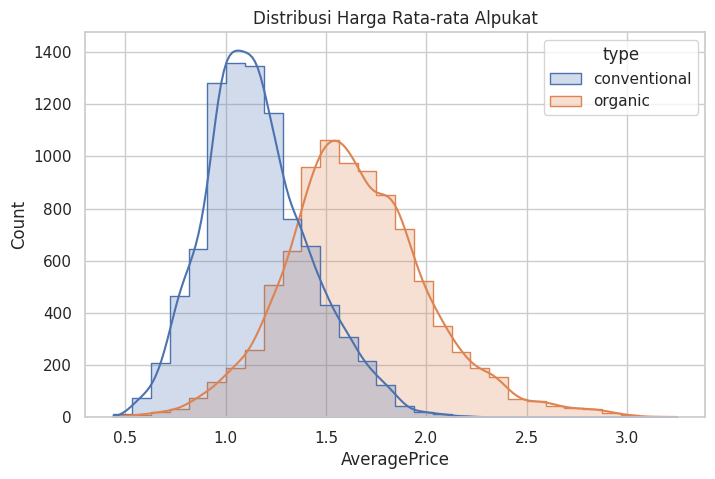

              mean  median  std
type                           
conventional  1.16    1.13 0.26
organic       1.65    1.63 0.36


In [ ]:
# Distribusi AveragePrice
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='AveragePrice', hue='type', kde=True, bins=30, element='step')
plt.title('Distribusi Harga Rata-rata Alpukat')
plt.show()
print(df.groupby('type')['AveragePrice'].agg(['mean','median','std']))

Histogram memperlihatkan sebaran harga rata-rata dan perbedaan distribusinya berdasarkan jenis alpukat. Nilai mean dan median membantu melihat pusat distribusi serta kemungkinan kemencengan data.

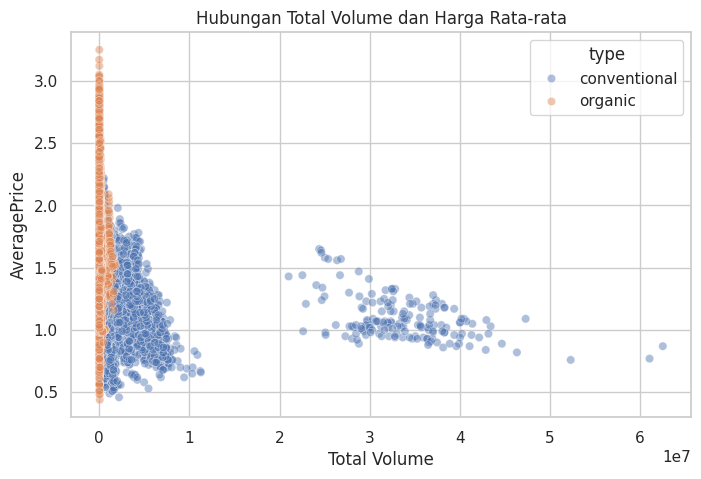

In [ ]:
# Hubungan harga dan volume
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Total Volume', y='AveragePrice', hue='type', alpha=.45)
plt.title('Hubungan Total Volume dan Harga Rata-rata')
plt.show()

Scatter plot digunakan untuk melihat apakah volume penjualan bergerak searah atau berlawanan dengan harga. Sebaran yang lebar menunjukkan bahwa hubungan harga dan volume tidak cukup dijelaskan oleh satu pola sederhana.

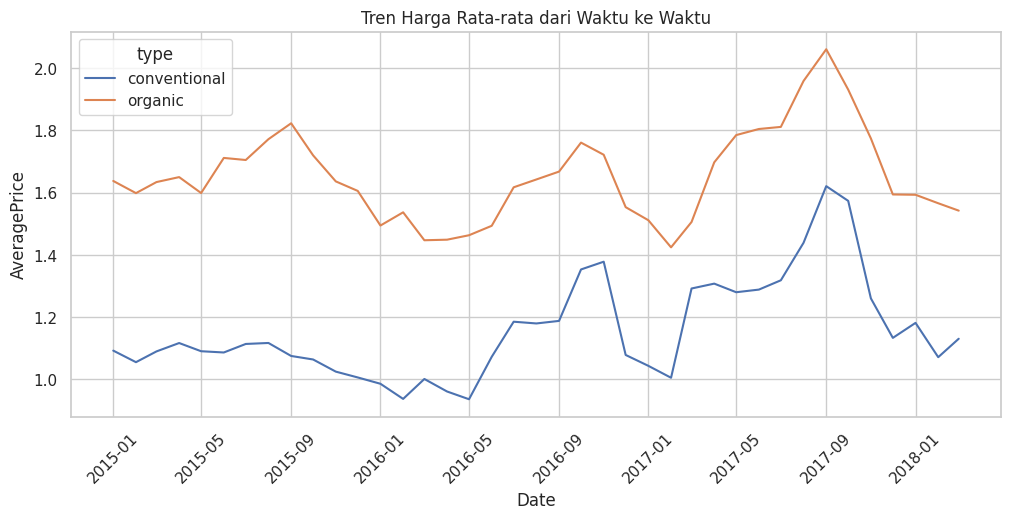

In [ ]:
# Tren harga per tahun
temp = df.copy()
temp['Date'] = pd.to_datetime(temp['Date'], errors='coerce')
trend = temp.groupby([pd.Grouper(key='Date', freq='MS'), 'type'])['AveragePrice'].mean().reset_index()
plt.figure(figsize=(12,5))
sns.lineplot(data=trend, x='Date', y='AveragePrice', hue='type')
plt.title('Tren Harga Rata-rata dari Waktu ke Waktu')
plt.xticks(rotation=45); plt.show()

Grafik garis memperlihatkan perubahan harga rata-rata dari waktu ke waktu untuk kedua jenis alpukat. Pola naik-turun dapat dipengaruhi waktu dan wilayah, sehingga grafik ini digunakan sebagai eksplorasi, bukan bukti penyebab perubahan harga.

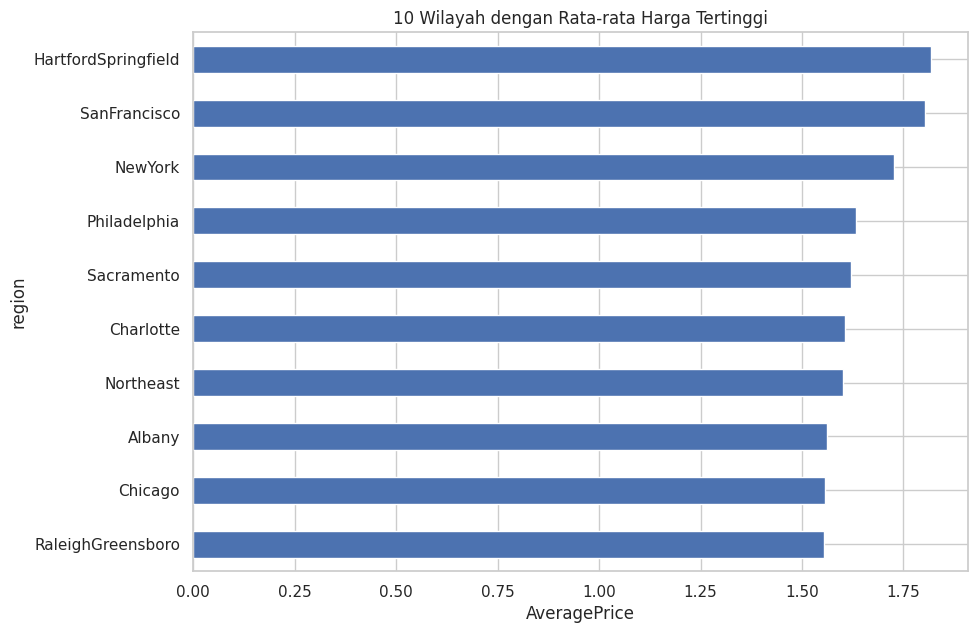

In [ ]:
# Rata-rata harga berdasarkan wilayah (10 wilayah dengan jumlah data terbanyak)
region_price = df.groupby('region')['AveragePrice'].mean().sort_values(ascending=False)
plt.figure(figsize=(10,7))
region_price.head(10).sort_values().plot(kind='barh')
plt.title('10 Wilayah dengan Rata-rata Harga Tertinggi')
plt.xlabel('AveragePrice'); plt.show()

Grafik wilayah membantu membandingkan rata-rata harga antarwilayah. Perbandingan ini perlu dilakukan pada wilayah detail; baris agregat nasional atau gabungan wilayah tidak boleh dicampur begitu saja dengan wilayah lokal.